In [1]:
%pip install qiskit qiskit-aer


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 46.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 84.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 77.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]


In [4]:

%pip install matplotlib


In [11]:

from qiskit import QuantumCircuit

# Create a circuit with one qubit
qc = QuantumCircuit(1)

# Display the circuit as text
print(qc.draw())



   
q: 
   


In [12]:

qc.h(0)

print(qc.draw())


   ┌───┐
q: ┤ H ├
   └───┘


In [13]:

# Create a new circuit with one qubit and one classical bit
qc = QuantumCircuit(1, 1)

# Apply Hadamard gate
qc.h(0)

# Measure the qubit and store the result
qc.measure(0, 0)

# Display the circuit
print(qc.draw())


     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [14]:

from qiskit_aer import AerSimulator

# Create our quantum simulator
simulator = AerSimulator()

# Run the experiment 1000 times
job = simulator.run(qc, shots=1000)

# Get the results
result = job.result()

# Count how many zeros and ones we got
counts = result.get_counts()

print(counts)


{'1': 505, '0': 495}


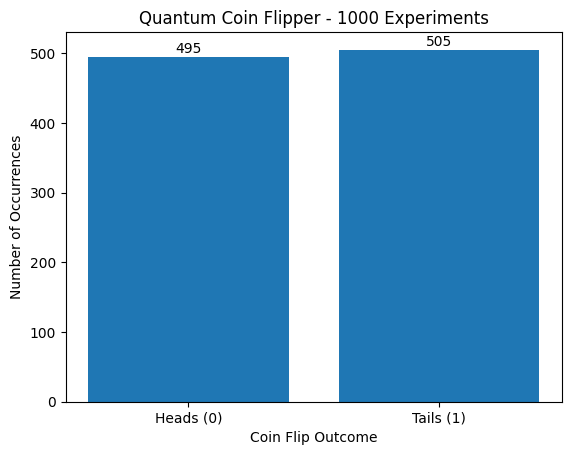

In [15]:

import matplotlib.pyplot as plt

# Convert quantum results into coin-flip labels
heads = counts.get('0', 0)
tails = counts.get('1', 0)

# Create the chart
plt.bar(['Heads (0)', 'Tails (1)'], [heads, tails])

# Add labels
plt.title('Quantum Coin Flipper - 1000 Experiments')
plt.xlabel('Coin Flip Outcome')
plt.ylabel('Number of Occurrences')

# Show the values above each bar
for i, value in enumerate([heads, tails]):
    plt.text(i, value + 5, str(value), ha='center')

plt.show()


In [16]:
import math
from qiskit import QuantumCircuit

# Create a fresh circuit
biased_qc = QuantumCircuit(1, 1)

# Apply a rotation gate
biased_qc.ry(math.pi / 3, 0)

# Measure the qubit
biased_qc.measure(0, 0)

# Display the circuit
print(biased_qc.draw())

     ┌─────────┐┌─┐
  q: ┤ Ry(π/3) ├┤M├
     └─────────┘└╥┘
c: 1/════════════╩═
                 0 


In [17]:
from qiskit_aer import AerSimulator

# Create the simulator
simulator = AerSimulator()

# Run the biased coin 1000 times
job = simulator.run(biased_qc, shots=1000)

# Retrieve the results
result = job.result()
biased_counts = result.get_counts()

# Display the results
print(biased_counts)

{'1': 277, '0': 723}


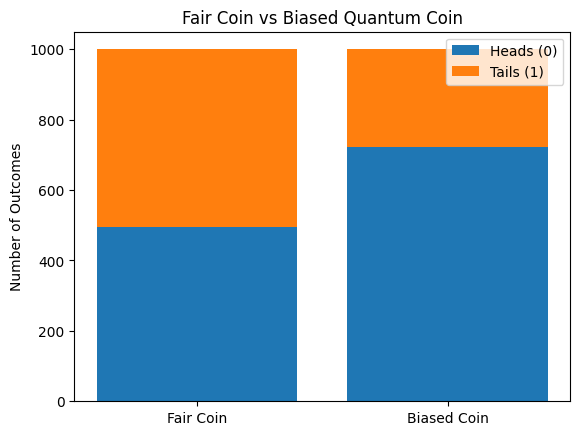

In [18]:
import matplotlib.pyplot as plt

# Results from our original fair coin
fair_heads = counts.get('0', 0)
fair_tails = counts.get('1', 0)

# Results from our biased coin
biased_heads = biased_counts.get('0', 0)
biased_tails = biased_counts.get('1', 0)

# Create comparison chart
labels = ['Fair Coin', 'Biased Coin']

heads = [fair_heads, biased_heads]
tails = [fair_tails, biased_tails]

plt.bar(labels, heads, label='Heads (0)')
plt.bar(labels, tails, bottom=heads, label='Tails (1)')

plt.title('Fair Coin vs Biased Quantum Coin')
plt.ylabel('Number of Outcomes')
plt.legend()

plt.show()

In [19]:
# Choose the percentage chance of getting Heads
heads_probability = 90

print("Heads probability:", heads_probability, "%")
print("Tails probability:", 100 - heads_probability, "%")

Heads probability: 90 %
Tails probability: 10 %


In [20]:
import math
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# Convert the Heads probability into a rotation angle
theta = 2 * math.acos(math.sqrt(heads_probability / 100))

# Create a fresh quantum circuit
adjustable_qc = QuantumCircuit(1, 1)

# Apply the calculated rotation
adjustable_qc.ry(theta, 0)

# Measure the qubit
adjustable_qc.measure(0, 0)

# Display the circuit
print(adjustable_qc.draw())

     ┌────────────┐┌─┐
  q: ┤ Ry(0.6435) ├┤M├
     └────────────┘└╥┘
c: 1/═══════════════╩═
                    0 


In [21]:
simulator = AerSimulator()

job = simulator.run(adjustable_qc, shots=1000)
result = job.result()

adjustable_counts = result.get_counts()

print("Your adjustable coin results:", adjustable_counts)

Your adjustable coin results: {'1': 111, '0': 889}


In [22]:
from IPython.display import display
import ipywidgets as widgets

heads_slider = widgets.IntSlider(
    value=90,
    min=0,
    max=100,
    step=5,
    description='Heads %:',
    continuous_update=False
)

display(heads_slider)

IntSlider(value=90, continuous_update=False, description='Heads %:', step=5)

In [23]:
import math
import matplotlib.pyplot as plt
from IPython.display import display
import ipywidgets as widgets
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()

def run_quantum_coin(heads_percentage):
    # Convert the selected probability into an angle
    theta = 2 * math.acos(math.sqrt(heads_percentage / 100))

    # Create a fresh circuit
    circuit = QuantumCircuit(1, 1)
    circuit.ry(theta, 0)
    circuit.measure(0, 0)

    # Run 1000 experiments
    result = simulator.run(circuit, shots=1000).result()
    counts = result.get_counts()

    # Get Heads and Tails
    heads = counts.get('0', 0)
    tails = counts.get('1', 0)

    # Display results
    print(f"Selected Heads probability: {heads_percentage}%")
    print(f"Actual Heads: {heads} ({heads / 10:.1f}%)")
    print(f"Actual Tails: {tails} ({tails / 10:.1f}%)")

    # Plot the results
    plt.figure(figsize=(6, 4))
    plt.bar(['Heads (0)', 'Tails (1)'], [heads, tails])
    plt.ylim(0, 1000)
    plt.title('Your Adjustable Quantum Coin')
    plt.ylabel('Number of outcomes')
    plt.show()

# Create the interactive slider
slider = widgets.interactive(
    run_quantum_coin,
    heads_percentage=widgets.IntSlider(
        value=90,
        min=0,
        max=100,
        step=5,
        description='Heads %:',
        continuous_update=False
    )
)

display(slider)

interactive(children=(IntSlider(value=90, continuous_update=False, description='Heads %:', step=5), Output()),…